# Lesson — Can we find delivery types without being told what they are?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kishan19/ds-with-cricket-basic-ML/blob/main/lessons/01-kmeans-clustering/lesson.ipynb)

**Concept:** K-means clustering
**Cricket question:** does a delivery's physics alone reveal what "kind" of ball it was?
**Data:** Hawk-Eye ball tracking for the IPL, from
[alittlefitness/HawkeyeStats](https://github.com/alittlefitness/HawkeyeStats)

> Sections are fixed by `docs/lesson-contract.md`. Do not add, remove or reorder them
> (the from-scratch appendix at the end is explicitly outside that contract).

**A note on this lesson's data.** The tracking numbers come from the
[HawkeyeStats](https://github.com/alittlefitness/HawkeyeStats) repo by
alittlefitness, a tidy CSV of the Hawk-Eye data the ICC's Pulselive API publishes
per delivery. All credit for collecting and tidying it goes there. That repo has
no licence, so this one doesn't redistribute the file. `make hawkeye` downloads it
into `data/raw/`, which is gitignored.

In [1]:
# Colab setup. Does nothing when run locally (use `make setup` and `make data` / `make hawkeye`).
# On Colab: clone the repo, install `cricketml`, and download this lesson's data.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO = "/content/ds-with-cricket-basic-ML"
    URL = "https://github.com/kishan19/ds-with-cricket-basic-ML.git"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "--depth=1", URL, REPO], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", REPO], check=True)
    os.environ["CRICKETML_ROOT"] = REPO  # so cricketml finds data/ inside the clone

    from cricketml.data import hawkeye

    hawkeye.download()

#test

In [ ]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from cricketml import SEED
from cricketml.data.hawkeye import (
    ATTRIBUTION,
    FEATURE_COLUMNS,
    PACE_STYLES,
    load_hawkeye,
)
from cricketml.viz import CATEGORICAL, annotate_source, use_theme

use_theme()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
rng = np.random.default_rng(SEED)
MS_TO_KPH = 3.6
SEED

1983

## 1. The cricket question

Turn the commentary off and look only at the numbers Hawk-Eye prints for one
ball: how fast it was, where it pitched, and where it passed the stumps. From
those numbers alone, could you tell a fast bowler from a spinner? Could you tell
left arm from right arm? Or would the numbers group the balls some other way,
one that no bowling-style label describes?

## 2. The data

**Grain:** one row per delivery, 628 IPL matches with Hawk-Eye coverage.

**Features: five measurements, all from the tracker, none about who bowled it.**

| column | meaning | unit |
|---|---|---|
| `ballSpeed` | speed out of the hand | m/s (× 3.6 for kph) |
| `pitchY` | how far from the batter's stumps it bounced: **length** | m |
| `pitchX` | how far across the pitch it bounced: **line** | m |
| `stumpsX` | how far across it passed the stumps | m |
| `stumpsY` | how high it passed the stumps | m |

**Held out, used only for interpretation:** `bowler`, and `bowler_type`, which
is `rightArmedBowl` and `bowlingStyle` combined into one label
(`RIGHT_FAST_SEAM`, `LEFT_FAST_SEAM`, `LEFT_ORTHODOX`, …).

**Exclusions, and why** (`cricketml.data.hawkeye.load_hawkeye`):
- **Tracker failures.** `ballSpeed == -1` is upstream's code for "no reading",
  and some rows have no coordinates at all. Imputing a measurement would invent
  a delivery nobody bowled, so these rows are dropped.
- **Impossible readings**, such as a ball that bounced 897 m down a 20 m pitch
  or passed the stumps 3 km underground. Anything outside `PLAUSIBLE_RANGES`
  (15–45 m/s, on or near the pitch) is dropped.
- Wides and no-balls are **kept**. They were still bowled, and their physics is real.

In [ ]:
raw = load_hawkeye(clean=False)
df = load_hawkeye()

no_reading = raw["ballSpeed"].le(0) | raw[list(FEATURE_COLUMNS)].isna().any(axis=1)
print(f"{len(raw):,} raw deliveries")
print(f"  tracker failed:      {no_reading.sum():>6,}  ({no_reading.mean():.1%})")
print(f"  impossible reading:  {len(raw) - no_reading.sum() - len(df):>6,}")
print(f"{len(df):,} kept, {df['bowler'].nunique()} bowlers")

FEATURES = list(FEATURE_COLUMNS)
df[FEATURES].describe().round(2)

149,424 raw deliveries
  tracker failed:       8,894  (6.0%)
  impossible reading:     297
140,233 kept, 341 bowlers


,ballSpeed,pitchX,pitchY,stumpsX,stumpsY
count,140233.00,140233.00,140233.00,140233.00,140233.00
mean,32.35,-0.15,6.30,-0.05,0.74
std,5.99,0.33,2.78,0.38,0.32
min,15.69,-1.93,-4.99,-1.91,-0.00
25%,26.00,-0.38,4.67,-0.30,0.57
50%,34.62,-0.18,6.30,-0.06,0.71
75%,37.62,0.05,8.09,0.18,0.88
max,43.40,1.99,16.73,1.90,2.84


## 3. The naive answer

Cricket already classifies every bowler: the scorecard's **arm and style**.
Here that's `bowler_type`, the two held-out columns combined. If `rightArmedBowl`
is `TRUE` and the style is `FAST_SEAM` the label is `RIGHT_FAST_SEAM`; if the arm
flag is `FALSE` it's `LEFT_FAST_SEAM`, and so on for every style. That gives ten
labels, and their coarsest split, **pace or spin**, is the one any clustering has
to recover before it gets credit for finding anything new.

The label describes the *bowler*, not the ball. It is decided before a delivery
is bowled, so none of it goes into the features.

In [ ]:
df["family"] = np.where(df["bowlingStyle"].isin(PACE_STYLES), "pace", "spin")
(
    df.groupby("bowler_type")
    .agg(deliveries=("bowler", "size"), bowlers=("bowler", "nunique"),
         family=("family", "first"), median_kph=("ballSpeed", "median"))
    .assign(median_kph=lambda t: (t.median_kph * MS_TO_KPH).round(1))
    .sort_values("deliveries", ascending=False)
)

,deliveries,bowlers,family,median_kph
bowler_type,,,,
RIGHT_FAST_SEAM,26699,48,pace,138.4
RIGHT_MEDIUM_SEAM,26347,44,pace,131.2
LEFT_SEAM,22091,112,pace,126.4
RIGHT_LEG_SPIN,17526,33,spin,88.4
RIGHT_OFF_SPIN,13434,31,spin,92.2
LEFT_ORTHODOX,11765,20,spin,92.8
RIGHT_SEAM,8347,22,pace,129.3
LEFT_FAST_SEAM,6451,17,pace,134.6
LEFT_MEDIUM_SEAM,6364,10,pace,131.0


**Check the label before you grade against it.** `SEAM` is not like the other
six styles. It looks like upstream's fallback for bowlers who were never given a
precise style, and their arm flag is unreliable. `LEFT_SEAM` holds 112 bowlers,
more than any other left-arm label, and its best-known names are right-armers.
`RIGHT_SEAM` even includes a leg-spinner:

In [ ]:
for label in ["LEFT_SEAM", "RIGHT_SEAM"]:
    top = df.loc[df["bowler_type"] == label, "bowler"].value_counts().head(8)
    print(f"{label:<10}", ", ".join(top.index))

LEFT_SEAM  Mohit Sharma, Mitchell McClenaghan, James Faulkner, Parvinder Awana, Lakshmipathy Balaji, Siddharth Trivedi, Albie Morkel, Kevon Cooper
RIGHT_SEAM Praveen Kumar, Vinay Kumar, Rajat Bhatia, Ashok Dinda, Varun Aaron, Stuart Binny, Ishwar Pandey, Munaf Patel


Mohit Sharma, Lakshmipathy Balaji and Parvinder Awana bowl right-arm, Iqbal
Abdulla is a left-arm spinner, and Samuel Badree bowls leg-spin. So `*_SEAM` is
kept in the tables below but treated as **unverified**. The other eight labels
check out against the names in them: Boult, Starc and Nehra are left-arm;
Bumrah, Malinga and Steyn are right-arm.

## 4. The idea

**In cricket.** Line up a season of deliveries with no labels attached, just the
numbers. Pick $K$ deliveries at random and call them prototypes. Assign every
real delivery to whichever prototype it most resembles. Recompute each prototype
as the average of the deliveries now assigned to it. Repeat until nothing moves.
Each prototype is now a "type" of delivery, discovered rather than defined by
anyone's eye for a bowling action.

**In maths.** K-means partitions $n$ deliveries into $K$ clusters
$C_1, \dots, C_K$ satisfying two constraints, which together put every delivery
in exactly one cluster:

$$C_1 \cup C_2 \cup \cdots \cup C_K = \{1, \dots, n\} \qquad C_k \cap C_{k'} = \emptyset \ \text{ for all } k \neq k'$$

chosen to minimise the total within-cluster variation:

$$\underset{C_1,\ldots,C_K}{\text{minimize}} \left\{ \sum_{k=1}^{K} W(C_k) \right\}$$

where a single cluster's variation is the average squared Euclidean distance
between every pair of deliveries inside it:

$$W(C_k) = \frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^{p} (x_{ij} - x_{i'j})^2$$

This equals twice the sum of squared distances to each cluster's centroid, which
is the form scikit-learn optimises with Lloyd's algorithm, the
assign-then-recompute loop described above.

**The assumption, and whether cricket satisfies it.** Squared Euclidean distance
treats a unit of every feature as equally important. Speed spreads over about
20 m/s, length over about 10 m, and line over about a metre. Left unscaled,
K-means would cluster on speed and length and all but ignore line. So every
feature is standardised before fitting.

## 5. Build it

The five standardised measurements go into K-means for a range of $K$. Two
numbers decide $K$. Inertia is the objective above; it always falls as $K$ grows,
so look for the elbow, not the minimum. Silhouette score measures how much better
a point fits its own cluster than the next-best one; it peaks rather than falls,
so it doesn't reward adding clusters for free.

In [ ]:
X = StandardScaler().fit_transform(df[FEATURES])

sil_sample = rng.choice(len(X), size=10_000, replace=False)
curve = pd.DataFrame([
    {
        "k": k,
        "inertia": (m := KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X)).inertia_,
        "silhouette": silhouette_score(X[sil_sample], m.labels_[sil_sample]),
    }
    for k in range(2, 20)
])
curve

,k,inertia,silhouette
0,2,512511.792,0.265
1,3,412476.154,0.239
2,4,346087.462,0.282
3,5,298237.902,0.274
4,6,263909.665,0.256
5,7,236547.783,0.262
6,8,218911.981,0.247
7,9,205800.800,0.225
8,10,194261.363,0.221
9,11,183894.040,0.217


4

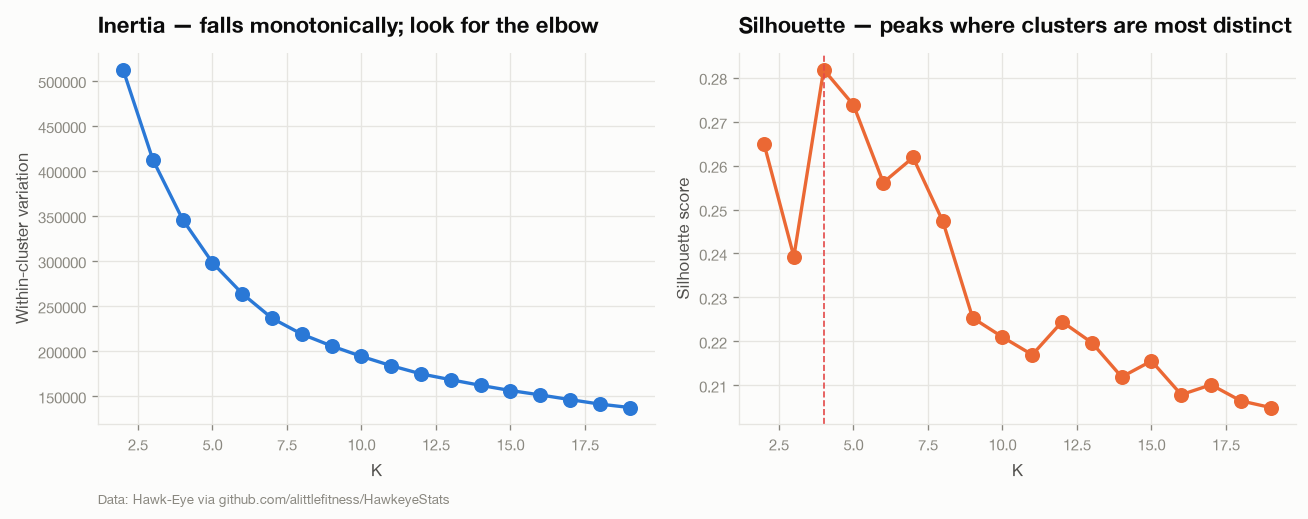

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(curve.k, curve.inertia, marker="o")
axes[0].set_title("Inertia — falls monotonically; look for the elbow")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Within-cluster variation")

best_k = int(curve.loc[curve.silhouette.idxmax(), "k"])
axes[1].plot(curve.k, curve.silhouette, marker="o", color=CATEGORICAL[1])
axes[1].axvline(best_k, color=CATEGORICAL[7], linestyle="--", linewidth=1)
axes[1].set_title("Silhouette — peaks where clusters are most distinct")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette score")

fig.tight_layout()
annotate_source(axes[0], text=ATTRIBUTION)
best_k

Drag $K$ below and watch the clusters split. The slider fits on a
20,000-delivery sample so it stays responsive; the $K$ chosen above came from
the full dataset.

In [ ]:
demo_idx = rng.choice(len(X), size=20_000, replace=False)
X_demo = X[demo_idx]
X_demo_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_demo)

def explore(k=best_k):
    labels = KMeans(n_clusters=k, random_state=SEED, n_init=5).fit_predict(X_demo)
    _fig, ax = plt.subplots(figsize=(7, 5.5))
    for c in range(k):
        m = labels == c
        ax.scatter(
            X_demo_2d[m, 0], X_demo_2d[m, 1],
            s=6, alpha=0.5, color=CATEGORICAL[c % len(CATEGORICAL)], label=f"cluster {c}",
        )
    ax.set_title(f"K = {k}, PCA-projected (20,000-delivery sample)")
    ax.legend(markerscale=3, loc="upper right")
    plt.show()

_ = widgets.interact(explore, k=widgets.IntSlider(min=2, max=8, value=best_k, continuous_update=False))

interactive(children=(IntSlider(value=4, continuous_update=False, description='k', max=8, min=2), Output()), _…

## 6. Judge it

Fit the chosen $K$ on every delivery, then read the clusters three ways:
1. **In cricket units.** What does each centre look like as a ball?
2. **Against `bowler_type`.** Which arm and style bowled the deliveries in each cluster?
3. **Against `bowler`.** Where do the deliveries of bowlers everyone knows end up?

In [ ]:
final_km = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit(X)
df = df.assign(cluster=final_km.labels_)

centres = df.groupby("cluster")[FEATURES].mean()
centres.insert(0, "kph", centres.pop("ballSpeed") * MS_TO_KPH)
centres.join(df["cluster"].value_counts(normalize=True).rename("share")).round(2)

,kph,pitchX,pitchY,stumpsX,stumpsY,share
cluster,,,,,,
0,131.91,-0.31,9.01,-0.17,1.03,0.32
1,119.00,0.28,5.84,0.42,0.67,0.20
2,133.09,-0.28,3.36,-0.27,0.41,0.16
3,91.19,-0.18,5.32,-0.12,0.67,0.32


Each centre can be read as a ball. The slowest is spin. Of the three pace
centres, one pitches fullest (smallest `pitchY`) and arrives lowest at the
stumps, which makes it full and yorker length. One pitches short of a length and
arrives about stump-high. The third is the odd one out. Its speed falls between
pace and spin, and its `pitchX` and `stumpsX` sit on the *other side* of middle
stump from every other cluster. Naming them from their centres, not from hard-coded
cluster numbers, keeps the names correct if a re-run shuffles the numbering:

In [ ]:
assert best_k == 4, "the names below describe the K=4 solution; re-read the centres"
order = centres.sort_values("kph").index
spin = order[0]
pace = centres.drop(spin)
full = pace["pitchY"].idxmin()
other_side = pace.drop(full)["pitchX"].idxmax()
(length,) = pace.index.difference([full, other_side])

NAMES = {spin: "spin", full: "full / yorker", length: "short of a length",
         other_side: "the other line"}
df["archetype"] = df["cluster"].map(NAMES)
centres.rename(index=NAMES).round(2)

,kph,pitchX,pitchY,stumpsX,stumpsY
cluster,,,,,
short of a length,131.91,-0.31,9.01,-0.17,1.03
the other line,119.00,0.28,5.84,0.42,0.67
full / yorker,133.09,-0.28,3.36,-0.27,0.41
spin,91.19,-0.18,5.32,-0.12,0.67


In [ ]:
by_type = pd.crosstab(df["archetype"], df["bowler_type"], normalize="index").round(2)
by_type.insert(0, "spin share", df.groupby("archetype")["family"].apply(lambda f: f.eq("spin").mean()).round(3))
by_type

bowler_type,spin share,LEFT_FAST_SEAM,LEFT_MEDIUM_SEAM,LEFT_ORTHODOX,LEFT_SEAM,LEFT_UNORTHODOX,RIGHT_FAST_SEAM,RIGHT_LEG_SPIN,RIGHT_MEDIUM_SEAM,RIGHT_OFF_SPIN,RIGHT_SEAM
archetype,,,,,,,,,,,
full / yorker,0.030,0.09,0.07,0.01,0.16,0.00,0.31,0.01,0.27,0.01,0.08
short of a length,0.003,0.06,0.06,0.00,0.17,0.00,0.33,0.00,0.29,0.00,0.08
spin,0.800,0.00,0.00,0.21,0.13,0.02,0.01,0.33,0.03,0.23,0.03
the other line,0.254,0.06,0.07,0.06,0.17,0.01,0.16,0.09,0.22,0.09,0.06


In [ ]:
trusted = ~df["bowlingStyle"].eq("SEAM")
print("How well do the clusters line up with the held-out labels? (ARI: 0 = chance, 1 = identical)")
print(f"  pace / spin:                     {adjusted_rand_score(df['family'], df['cluster']):.3f}")
print(f"  bowler_type (all 10 labels):     {adjusted_rand_score(df['bowler_type'], df['cluster']):.3f}")
print(f"  bowler_type (no *_SEAM):         {adjusted_rand_score(df.loc[trusted, 'bowler_type'], df.loc[trusted, 'cluster']):.3f}")
print(f"  rightArmedBowl (no *_SEAM):      {adjusted_rand_score(df.loc[trusted, 'rightArmedBowl'], df.loc[trusted, 'cluster']):.3f}")

How well do the clusters line up with the held-out labels? (ARI: 0 = chance, 1 = identical)
  pace / spin:                     0.251
  bowler_type (all 10 labels):     0.133


  bowler_type (no *_SEAM):         0.200
  rightArmedBowl (no *_SEAM):      0.005


In [ ]:
famous = ["Jasprit Bumrah", "Lasith Malinga", "Dale Steyn", "Trent Boult", "Mitchell Starc",
          "Bhuvneshwar Kumar", "Rashid Khan", "Yuzvendra Chahal", "Sunil Narine",
          "Ravindra Jadeja", "Kuldeep Yadav"]
per_bowler = pd.crosstab(df["bowler"], df["archetype"], normalize="index")
per_bowler = per_bowler.join(df.groupby("bowler")[["bowler_type"]].first())
per_bowler = per_bowler.join(df["bowler"].value_counts().rename("deliveries"))
per_bowler.loc[[b for b in famous if b in per_bowler.index]].round(2)

,full / yorker,short of a length,spin,the other line,bowler_type,deliveries
bowler,,,,,,
Jasprit Bumrah,0.30,0.57,0.02,0.11,RIGHT_FAST_SEAM,2373
Lasith Malinga,0.41,0.33,0.02,0.23,RIGHT_FAST_SEAM,1822
Dale Steyn,0.19,0.60,0.01,0.20,RIGHT_FAST_SEAM,1222
Trent Boult,0.35,0.39,0.02,0.25,LEFT_FAST_SEAM,1358
Mitchell Starc,0.47,0.31,0.00,0.22,LEFT_FAST_SEAM,543
Bhuvneshwar Kumar,0.26,0.55,0.01,0.17,RIGHT_MEDIUM_SEAM,2756
Rashid Khan,0.01,0.01,0.86,0.13,RIGHT_LEG_SPIN,1712
Yuzvendra Chahal,0.00,0.00,0.83,0.17,RIGHT_LEG_SPIN,2380
Sunil Narine,0.01,0.00,0.84,0.14,RIGHT_OFF_SPIN,2961


**In prose.** Pace against spin mostly comes out. Both length clusters are
almost pure pace, with 3% spin or less. Rashid Khan, Chahal, Narine, Jadeja and
Kuldeep each put about 80 to 85% of their deliveries in the slowest cluster.
That cluster is 80% spin by label, and most of the remaining 20% is `*_SEAM`,
the label section 3 showed can't be trusted. K-means never saw the label, so
this is the sanity check passing. The pace/spin ARI is only 0.25, and the
reason is the fourth cluster, which mixes both (see section 7).

Among the pace bowlers, the clusters don't match the scorecard labels at all.
Every pace cluster has roughly the same mix of `RIGHT_FAST_SEAM`,
`RIGHT_MEDIUM_SEAM` and `LEFT_FAST_SEAM`. The split inside pace is **length**:
back of a length versus full. That is a property of the *ball*, not of the
*bowler*, which the bowler-level table shows directly. Malinga, the yorker
specialist, puts more of his deliveries in "full / yorker" than in "short of a
length". Bumrah, Steyn and Bhuvneshwar sit mostly in "short of a length", with
a large full-length share of their own. Every seamer bowls both, so no seamer
belongs to one cluster.

Arm is invisible. `LEFT_FAST_SEAM` makes up 6 to 9% of both length clusters,
and the ARI against `rightArmedBowl` is essentially zero (0.005). That is an honest result, not
a failure. Arm shows up in release position and angle of approach, and neither
is among these five columns. The "other line" cluster is explained in section 7:
it isn't about bowlers.

So the answer to the cricket question is: speed separates pace from spin; length
separates full pace from short pace; and nothing in these five numbers says which
arm bowled the ball.

## 7. What it gets wrong

- **One cluster is about the batter, not the bowler.** Hawk-Eye's `X`
  coordinates are fixed to the pitch, not to the batter's stance. A ball on a
  left-hander's off stump sits on the opposite side of middle to the same ball
  bowled to a right-hander. The table below shows who was batting in each
  cluster. The "other line" cluster is 74% left-handed batters, against 24–29%
  everywhere else. K-means has rediscovered the *batter's* stance, and it mixes
  pace and spin because both are bowled to left-handers. → *batter-relative features: mirror
  `pitchX`/`stumpsX` for left-handers before clustering*

In [ ]:
pd.crosstab(df["archetype"], df["rightHandedBat"].map({True: "right-hander", False: "left-hander"}),
            normalize="index").round(3)

rightHandedBat,left-hander,right-hander
archetype,,
full / yorker,0.237,0.763
short of a length,0.273,0.727
spin,0.292,0.708
the other line,0.744,0.256


- **The label used to grade the clusters is itself noisy.** Section 3 showed that
  `*_SEAM` is a fallback style with an unreliable arm flag. Grading against a
  label without checking it first would have blamed K-means for upstream's gaps.
  → *audit a validation label as carefully as a feature*
- **The clusters describe deliveries, so they can't describe bowlers.** Every
  seamer bowls full *and* short, so their deliveries spread across clusters. A
  bowler "type" needs a bowler-level unit: each bowler's *distribution* of
  deliveries, clustered in turn. → *aggregation to the right grain; mixture
  models*
- **Standardising gives every feature the same vote.** Line, length and height
  get exactly the same weight as speed. That follows from how distance is
  computed, not from any view about what matters in cricket.
  → *feature weighting, domain-informed distance metrics*
- **$K$ was chosen by silhouette on a 10,000-row subsample**, for speed, and
  the silhouette differences between neighbouring $K$ are small. A different
  season could pick a different $K$. → *stability checks under resampling*
- **K-means assumes round, similarly sized clusters.** Length is a continuum
  from yorker to bouncer, not two blobs, so K-means has to cut it somewhere.
  → *Gaussian mixture models, DBSCAN*

**Next:** a later lesson asks whether these five numbers can be squeezed into two
without losing what makes the clusters distinct. That's PCA, and what "distance"
means once the axes aren't the original measurements.

## Appendix — K-means from scratch (optional)

Everything above calls `sklearn.cluster.KMeans`. Below is the same algorithm,
Lloyd's algorithm, written out by hand, because watching it converge teaches
more than reading its name. This isn't one of the seven fixed sections; skip it
if the lesson has already made its point.

In [ ]:
def kmeans_from_scratch(X: np.ndarray, k: int, seed: int, max_iter: int = 100):
    """Assign, recompute, repeat until nothing moves. One random start."""
    local_rng = np.random.default_rng(seed)
    centroids = X[local_rng.choice(len(X), size=k, replace=False)]
    for _ in range(max_iter):
        # Assign: each point to its nearest centroid (squared Euclidean).
        distances = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        labels = distances.argmin(axis=1)
        # Recompute: each centroid becomes the mean of the points assigned to it.
        new_centroids = np.array([
            X[labels == c].mean(axis=0) if (labels == c).any() else centroids[c]
            for c in range(k)
        ])
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
    inertia = ((X - centroids[labels]) ** 2).sum()
    return labels, inertia

# For understanding, not for 140,000 rows — a small sample keeps this readable.
scratch_sample = X[rng.choice(len(X), size=2_000, replace=False)]
labels_sklearn = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit_predict(scratch_sample)

# Cluster *labels* are arbitrary (this run's "0" isn't that run's "0"), so
# compare partitions, not label numbers, via the adjusted Rand index.
rows = []
for seed in range(10):
    labels, inertia = kmeans_from_scratch(scratch_sample, k=best_k, seed=seed)
    rows.append({"seed": seed, "ari": adjusted_rand_score(labels, labels_sklearn), "inertia": inertia})
starts = pd.DataFrame(rows)
starts.round(3)

,seed,ari,inertia
0,0,0.962,5101.410
1,1,0.986,5101.044
2,2,0.998,5101.043
3,3,0.998,5101.043
4,4,0.336,5341.331
5,5,0.980,5101.072
6,6,0.998,5101.043
7,7,0.986,5101.044
8,8,0.961,5101.559
9,9,0.989,5100.971


Lloyd's algorithm only ever improves on where it started, so each random start
settles into the nearest basin. Not every basin is the best one. Look at the
spread in inertia and ARI above: a start that lands in a worse basin gives a
different partition from scikit-learn's. That is why `KMeans` defaults to
`n_init=10` rather than `1`: it restarts several times and keeps the
lowest-inertia result.

In [ ]:
best = starts.loc[starts["inertia"].idxmin()]
worst = starts.loc[starts["inertia"].idxmax()]
print(f"worst of 10 starts: ARI = {worst.ari:.3f}   inertia = {worst.inertia:,.0f}")
print(f"best of 10 starts:  ARI = {best.ari:.3f}   inertia = {best.inertia:,.0f}")

worst of 10 starts: ARI = 0.336   inertia = 5,341
best of 10 starts:  ARI = 0.989   inertia = 5,101
